In [87]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [89]:
#This is a relative path.
DATA_DIR = Path('/Users/jnoda/Desktop/Certificate/Cyclistic Data 2019 ')
#This folder will hold the exported files and charts 
OUTPUT_DIR = Path('/Users/jnoda/Desktop/Certificate/Cyclistic Data 2019 /outputs')
#Create the outputs folder if it does not exist.
#exist_ok=True prevents an error if the folder already exists.
OUTPUT_DIR.mkdir(exist_ok=True)

In [91]:
#Creates a dictionary with each quarter as the key and the filename as the value.
files = {
    "Q1": "Divvy_Trips_2019_Q1.csv",
    "Q2": "Divvy_Trips_2019_Q2.csv",
    "Q3": "Divvy_Trips_2019_Q3.csv",
    "Q4": "Divvy_Trips_2019_Q4.csv"
}
#Q2 has different column names.
#This dictionary tells pandas which old name becomes the new name
q2_names = {
    "01 - Rental Details Rental ID": "trip_id",
    "01 - Rental Details Local Start Time": "start_time",
    "01 - Rental Details Local End Time": "end_time",
    "01 - Rental Details Bike ID": "bikeid",
    "01 - Rental Details Duration In Seconds Uncapped": "tripduration",
    "03 - Rental Start Station ID": "from_station_id",
    "03 - Rental Start Station Name": "from_station_name",
    "02 - Rental End Station ID": "to_station_id",
    "02 - Rental End Station Name": "to_station_name",
    "User Type": "usertype",
    "Member Gender": "gender",
    "05 - Member Details Member Birthday Year": "birthyear"
}
#This is a list of the columns we expect and their order
expected_columns = [
    "trip_id", "start_time", "end_time", "bikeid",
    "tripduration", "from_station_id", "from_station_name",
    "to_station_id", "to_station_name",
    "usertype", "gender", "birthyear"
]
#Empty list. We will add one DataFrama for each quarter
quarters = []

In [92]:
#items() gives us each dictionary key and value together
for quarter, filename in files.items():
    #The / joins a folder path and a filename.
    # dtype="string" initially reads every field as text.
    part = pd.read_csv(
        DATA_DIR / filename,
        dtype="string"
    )
    # Standardize any matching Q2 column names.
    # Columns not present in the dictionary retain their original names.
    part = part.rename(columns=q2_names)
    
    # set() compares column membership without considering order.
    # Also check the count so unexpected duplicate column names are flagged.
    if (set(part.columns) != set(expected_columns) 
        or len(part.columns) != len(expected_columns)
       ):
        # Stop rather than silently combine incompatible data.
        raise ValueError(
            f"{quarter}: unexpected columns: {list(part.columns)}"
        )
    # Select the expected columns in the specified order.
    # .copy() creates a separate DataFrame for the next changes.
    part = part[expected_columns].copy()
    
    # Record where each row came from.
    # Every row in this quarter gets the same quarter label.
    part["source_quarter"] = quarter
    # Add this quarter's DataFrame to the list.
    quarters.append(part)

# Stack the quarterly DataFrames vertically.
# ignore_index=True creates a new continuous row index.
raw = pd.concat(quarters, ignore_index=True)

## Testing during code writing
#Group rows by quarter and count the rows in each group.
#print(raw.groupby("source_quarter").size())
#len() returns the number of rows in a DataFrame.
#print("Total rows:", len(raw))

In [93]:
#Preserve raw and perform transformations on a separate DataFrame.
df = raw.copy()

# Repeat the same conversion for both timestamp columns.
for column in ["start_time", "end_time"]:
    df[column] = pd.to_datetime(
        df[column],
        # Allow pandas to interpret different date formats.
        format="mixed",
        # Unparseable dates become NaT, pandas' missing datetime value.
        errors="coerce"
    )
# Remove thousands separators from duration text
# Convert the cleaned text to numbers.
# Unparseable values become missing rather than stopping execution.
df["duration_seconds"] = pd.to_numeric(
    df["tripduration"].str.replace(",", "", regex=False),
    errors="coerce"
)

# Subtracting timestamps produces a timedelta: an amount of elapsed time.
# .dt.total_seconds() expresses that interval as seconds.
df["elapsed_seconds"] = (
    df["end_time"] - df["start_time"]
).dt.total_seconds()

# Compare the source duration with the timestamp-derived duration.
df["duration_difference_seconds"] = (
    df["duration_seconds"] - df["elapsed_seconds"]
)

# Translate source labels into clearer reporting labels.
# Unexpected source labels become missing values.
df["user_type"] = df["usertype"].map({
    "Customer": "Casual",
    "Subscriber": "Member"
})
# A Series is a labeled, one-dimensional collection.
# Here, labels describe quality checks and values contain their counts.
audit = pd.Series({
    "raw_rows": len(df),
    
    # Exact duplicates match across every original column.
    # By default, duplicated() marks occurrences after the first.
    "exact_duplicate_rows": raw.duplicated().sum(),
    "duplicate_trip_ids": df["trip_id"].duplicated().sum(),
    # isna() identifies missing values.
    "missing_trip_ids": df["trip_id"].isna().sum(),
    "invalid_start_times": df["start_time"].isna().sum(),
    "invalid_end_times": df["end_time"].isna().sum(),
    "invalid_durations": df["duration_seconds"].isna().sum(),
    # le(0) means "less than or equal to zero".
    "nonpositive_durations": df["duration_seconds"].le(0).sum(),
    # gt() means "greater than".
    # 86,400 seconds = 24 hours.
    "durations_over_24_hours": df["duration_seconds"].gt(86400).sum(),
    "unknown_user_types": df["user_type"].isna().sum(),
    # abs() removes the sign: absolute value.
    "duration_discrepancies_over_1_second":
        df["duration_difference_seconds"].abs().gt(1).sum()
})

print(audit)
audit.to_csv(OUTPUT_DIR / "quality_audit.csv", header=["count"])

raw_rows                                3818004
exact_duplicate_rows                          0
duplicate_trip_ids                            0
missing_trip_ids                              0
invalid_start_times                           0
invalid_end_times                             0
invalid_durations                             0
nonpositive_durations                         0
durations_over_24_hours                    1848
unknown_user_types                            0
duration_discrepancies_over_1_second        103
dtype: int64


In [94]:
# Choose the fields useful for investigating duration problems.
review_columns = [
    "trip_id", "source_quarter", "user_type",
    "start_time", "end_time",
    "duration_seconds", "elapsed_seconds",
    "duration_difference_seconds"
]
# Find the 20 rows with the largest reported durations.
print(
    df.nlargest(20, "duration_seconds")[review_columns]
)
# .loc[rows, columns] selects rows and columns by label/condition.
# .head(20) displays only the first 20 selected rows.
print(
    df.loc[
        df["duration_difference_seconds"].abs().gt(1),
        review_columns
    ].head(20)
)

          trip_id source_quarter user_type          start_time  \
148897   21920842             Q1    Casual 2019-02-14 14:44:13   
1753537  23798837             Q3    Member 2019-07-16 18:17:58   
3189137  25302386             Q4    Casual 2019-10-06 13:57:02   
1839638  23889502             Q3    Member 2019-07-22 12:09:36   
3367117  25487192             Q4    Casual 2019-10-19 15:14:50   
1669835  23710210             Q3    Casual 2019-07-12 13:08:10   
2047113  24107150             Q3    Casual 2019-08-01 18:45:47   
1630590  23661214             Q3    Casual 2019-07-10 10:25:13   
1618591  23648641             Q3    Casual 2019-07-09 17:28:05   
1756534  23801970             Q3    Casual 2019-07-16 20:44:13   
2128692  24194299             Q3    Casual 2019-08-05 17:13:20   
1682846  23723936             Q3    Casual 2019-07-12 22:44:18   
1789268  23836329             Q3    Casual 2019-07-19 05:42:57   
2046503  24106513             Q3    Casual 2019-08-01 18:24:31   
2259521  2

In [95]:
# A trip is eligible if it satisfies every condition below.
eligible = (
    df["trip_id"].notna()
    & df["start_time"].ge(pd.Timestamp("2019-01-01"))
    & df["start_time"].lt(pd.Timestamp("2020-01-01"))
    & df["end_time"].notna()
    & df["duration_seconds"].gt(0)
    & df["user_type"].notna()
)

# Select eligible rows and create a separate working DataFrame.
analysis = df.loc[eligible].copy()

print("Included rows:", len(analysis))

# ~ reverses a Boolean condition.
# Eligible rows become False; excluded rows become True.
print("Excluded rows:", (~eligible).sum())

# Check row counts and start-date boundaries for each quarter.
print(
    analysis.groupby("source_quarter")["start_time"]
    .agg(["count", "min", "max"])
)

Included rows: 3818004
Excluded rows: 0
                  count                 min                 max
source_quarter                                                 
Q1               365069 2019-01-01 00:04:37 2019-03-31 23:53:48
Q2              1108163 2019-04-01 00:02:22 2019-06-30 23:59:05
Q3              1640718 2019-07-01 00:00:27 2019-09-30 23:59:37
Q4               704054 2019-10-01 00:01:39 2019-12-31 23:57:17


In [101]:
# Create a flag rather than immediately deleting long records.
analysis["over_24_hours"] = (
    analysis["duration_seconds"] > 86400
)

# Create a second dataset containing trips at most 24 hours long.
under_24h = analysis.loc[
    ~analysis["over_24_hours"]
].copy()

# Summarize both versions.
# Dictionary keys become labels in the combined output.
sensitivity = pd.concat({
    "All eligible trips": (
        analysis.groupby("user_type")["duration_seconds"]
        .agg(["count", "mean", "median"])
    ),
    "Trips at most 24 hours": (
        under_24h.groupby("user_type")["duration_seconds"]
        .agg(["count", "mean", "median"])
    )
})

print(sensitivity)
sensitivity.to_csv(OUTPUT_DIR / "duration_sensitivity.csv")

                                    count         mean  median
                       user_type                              
All eligible trips     Casual      880637  3420.885729  1549.0
                       Member     2937367   859.383275   588.0
Trips at most 24 hours Casual      879290     2365.535  1547.0
                       Member     2936866   775.632406   588.0


In [103]:
# Convert seconds to minutes for easier interpretation.
analysis["duration_minutes"] = (
    analysis["duration_seconds"] / 60
)

duration_summary = (
    analysis.groupby("user_type")["duration_minutes"]
    .agg(
        trips="size",
        mean_minutes="mean",
        median_minutes="median",
        # Quantiles describe values at points in the distribution.
        p90_minutes=lambda s: s.quantile(0.90),
        p95_minutes=lambda s: s.quantile(0.95),
        p99_minutes=lambda s: s.quantile(0.99),
        maximum_minutes="max",
        # The mean of a Boolean series is its proportion of True values.
        # Multiplying by 100 expresses that proportion as a percentage.
        percent_over_20_minutes=lambda s: s.gt(20).mean() * 100,
        percent_over_60_minutes=lambda s: s.gt(60).mean() * 100,
        percent_over_24_hours=lambda s: s.gt(1440).mean() * 100
    )
)
# Round only the displayed result.
print(duration_summary.round(2))
duration_summary.to_csv(OUTPUT_DIR / "duration_summary.csv")

             trips  mean_minutes  median_minutes  p90_minutes  p95_minutes  \
user_type                                                                    
Casual      880637         57.01           25.82        81.38       113.65   
Member     2937367         14.32             9.8         24.9        31.18   

           p99_minutes  maximum_minutes  percent_over_20_minutes  \
user_type                                                          
Casual          203.14         177140.0                    63.42   
Member           44.62        150943.88                    16.66   

           percent_over_60_minutes  percent_over_24_hours  
user_type                                                  
Casual                       16.52                   0.15  
Member                        0.42                   0.02  


In [105]:
# .dt gives access to datetime properties.
analysis["hour"] = analysis["start_time"].dt.hour
# Monday = 0, Tuesday = 1, ..., Sunday = 6.
analysis["weekday_number"] = analysis["start_time"].dt.dayofweek
# January = 1, ..., December = 12.
analysis["month"] = analysis["start_time"].dt.month
# Convert weekday numbers into two categories.
analysis["day_type"] = analysis["weekday_number"].map({
    0: "Weekday", 1: "Weekday", 2: "Weekday",
    3: "Weekday", 4: "Weekday",
    5: "Weekend", 6: "Weekend"
})

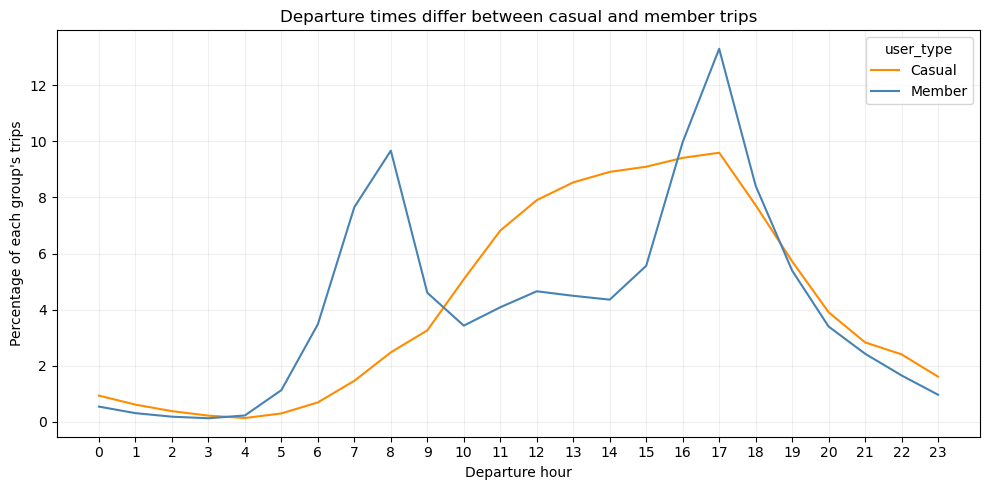

In [107]:
# Count trips for every combination of departure hour and user type.
# Ensure every hour from 0 through 23 appears.
# Missing hours receive a count of zero.
hour_counts = pd.crosstab(
    analysis["hour"],
    analysis["user_type"]
).reindex(range(24), fill_value=0)

# Sum each column to get each group's total trips.
group_totals = hour_counts.sum(axis=0)

# Divide each hourly count by its own group's total.
# axis=1 matches the denominator labels to the table's columns.
hour_percent = (
    hour_counts.div(group_totals, axis=1) * 100
)
# A DataFrame's .plot() method uses matplotlib.
# It returns an Axes object, stored here as ax.
ax = hour_percent.plot(
    figsize=(10, 5),
    color={"Casual": "darkorange", "Member": "steelblue"}
)
# Set chart text.
ax.set(
    title="Departure times differ between casual and member trips",
    xlabel="Departure hour",
    ylabel="Percentage of each group's trips"
)
# Show every hour on the horizontal axis.
ax.set_xticks(range(24))
# Add faint gridlines.
ax.grid(alpha=0.2)
# Adjust spacing to reduce clipping.
plt.tight_layout()
# Save before displaying.
plt.savefig(OUTPUT_DIR / "hourly_trip_shares.png", dpi=300)
plt.show()

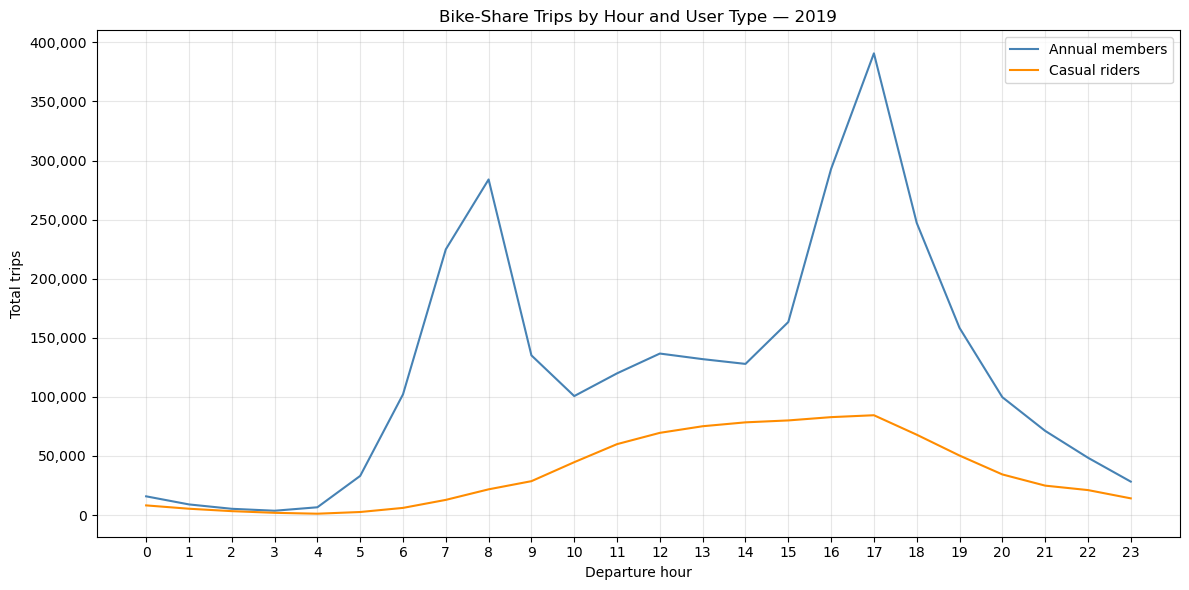

In [109]:
#Total trips by hour and user type

# Create the figure and its plotting area.
fig, ax = plt.subplots(figsize=(12, 6))

# Plot member trip counts.
ax.plot(
    hour_counts.index,
    hour_counts["Member"],
    label="Annual members",
    color="steelblue"
)

# Plot casual trip counts.
ax.plot(
    hour_counts.index,
    hour_counts["Casual"],
    label="Casual riders",
    color="darkorange"
)

ax.set_title("Bike-Share Trips by Hour and User Type — 2019")
ax.set_xlabel("Departure hour")
ax.set_ylabel("Total trips")

# Show every hour on the horizontal axis.
ax.set_xticks(range(24))

# Format large counts with commas.
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, position: f"{value:,.0f}")
)

ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

# Export the chart to the outputs folder.
fig.savefig(
    OUTPUT_DIR / "rides_by_hour.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

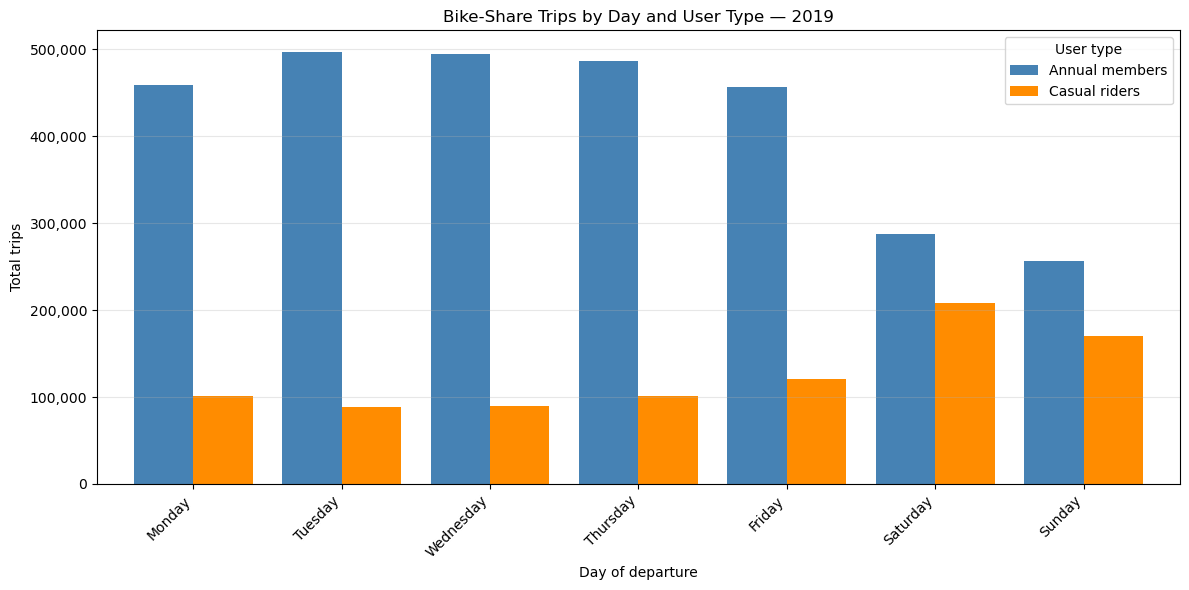

In [85]:
#Total trips by day of the week and user type

# Count trips for each weekday and user type.
day_counts = pd.crosstab(
    analysis["weekday_number"],
    analysis["user_type"]
).reindex(range(7), fill_value=0)

# Replace weekday numbers with readable labels.
day_counts.index = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Select the column order so members appear first.
# Each weekday gets two adjacent bars.
ax = day_counts[["Member", "Casual"]].plot(
    kind="bar",
    figsize=(12, 6),
    color=["steelblue", "darkorange"],
    width=0.8
)

ax.set_title("Bike-Share Trips by Day and User Type — 2019")
ax.set_xlabel("Day of departure")
ax.set_ylabel("Total trips")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, position: f"{value:,.0f}")
)

# Tilt the day labels for readability.
plt.xticks(rotation=45, ha="right")

ax.legend(
    ["Annual members", "Casual riders"],
    title="User type"
)

ax.grid(axis="y", alpha=0.3)

# Get the figure containing this plotting area.
fig = ax.get_figure()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "rides_by_day.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [79]:
# Create one row for every calendar date in 2019.
calendar = pd.DataFrame({
    "date": pd.date_range("2019-01-01", "2019-12-31")
})
# Label each date.
calendar["day_type"] = calendar["date"].dt.dayofweek.map({
    0: "Weekday", 1: "Weekday", 2: "Weekday",
    3: "Weekday", 4: "Weekday",
    5: "Weekend", 6: "Weekend"
})
# Count trips by day category and user type.
day_totals = pd.crosstab(
    analysis["day_type"],
    analysis["user_type"]
)
# Count how many calendar days belong to each category.
calendar_days = calendar["day_type"].value_counts()

# Divide each row by its number of calendar days.
# axis=0 aligns the denominators with row labels.
daily_average = day_totals.div(calendar_days, axis=0)

print("Calendar days:")
print(calendar_days)

print("Average trips per calendar day:")
print(daily_average.round(1))

# Compare casual weekend activity with casual weekday activity.
casual_weekend_ratio = (
    daily_average.loc["Weekend", "Casual"]
    / daily_average.loc["Weekday", "Casual"]
)

Calendar days:
day_type
Weekday    261
Weekend    104
Name: count, dtype: int64
Average trips per calendar day:
user_type  Casual  Member
day_type                 
Weekday    1924.9  9172.3
Weekend    3636.9  5225.0


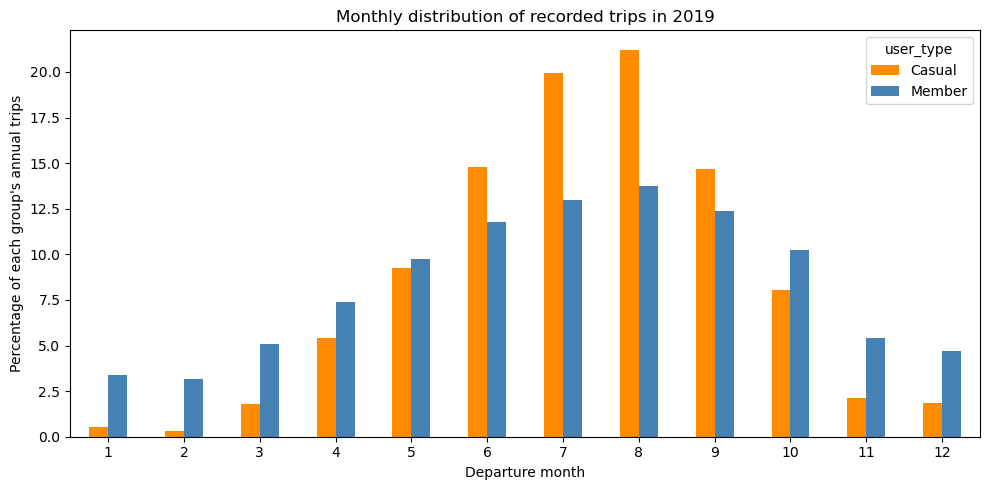

In [81]:
# Count trips by departure month and user type.
month_counts = pd.crosstab(
    analysis["month"],
    analysis["user_type"]
).reindex(range(1, 13), fill_value=0)

# Express each month's count as a share of that group's annual trips.
month_percent = (
    month_counts.div(month_counts.sum(axis=0), axis=1) * 100
)

# Plot the monthly shares.
ax = month_percent.plot(
    kind="bar",
    figsize=(10, 5),
    color={
        "Casual": "darkorange",
        "Member": "steelblue"
    }
)

ax.set(
    title="Monthly distribution of recorded trips in 2019",
    xlabel="Departure month",
    ylabel="Percentage of each group's annual trips"
)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "monthly_trip_shares.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# index=True retains row labels such as hours and months.
hour_counts.to_csv(
    OUTPUT_DIR / "hourly_trip_counts.csv",
    index=True
)

hour_percent.to_csv(
    OUTPUT_DIR / "hourly_trip_percentages.csv",
    index=True
)

day_totals.to_csv(
    OUTPUT_DIR / "weekday_weekend_trip_counts.csv",
    index=True
)

daily_average.to_csv(
    OUTPUT_DIR / "average_trips_per_calendar_day.csv",
    index=True
)

month_counts.to_csv(
    OUTPUT_DIR / "monthly_trip_counts.csv",
    index=True
)

month_percent.to_csv(
    OUTPUT_DIR / "monthly_trip_percentages.csv",
    index=True
)